# PixPay — Drivers de churn

Entrada: `data/clientes_pixpay_limpo.csv` (somente leitura). Funções em `scripts/analisar_drivers.py`.
Tudo aqui é **associação, não causalidade**.

In [1]:
import sys
from pathlib import Path

RAIZ = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "scripts").exists())
sys.path.insert(0, str(RAIZ / "scripts"))

import matplotlib.pyplot as plt
import pandas as pd
import analisar_drivers as ad
from investigar_transacoes import carregar_limpo

pd.set_option("display.width", 200)
df = carregar_limpo(RAIZ / "data" / "clientes_pixpay_limpo.csv")
df.shape

(10000, 16)

## Passo 1 — Validar a premissa do briefing (churn real vs. 8%)

Hipótese a testar: o churn mensal é 8%. Calculamos o churn de abril/2026 com três denominadores, com IC 95% (Wilson).

In [2]:
r1 = ad.validar_premissa(df)
r1["denominadores"]

,denominador,clientes,cancelaram,churn_%,ic95_inferior_%,ic95_superior_%,diferenca_vs_8%_pp
0,Base total (todas as linhas),10000,1353,13.53,12.87,14.21,5.53
1,Cadastrados antes de 01/04/2026,9990,1352,13.53,12.88,14.22,5.53
2,Ativos em 01/04/2026 (início do mês),9990,1352,13.53,12.88,14.22,5.53


### O dataset consegue mostrar a tendência de 6 meses?

In [3]:
pd.Series(r1["cobertura"], name="valor").to_frame()

,valor
cadastro_min,01/01/2024
cadastro_max,01/04/2026
cancelamento_min,01/04/2026
cancelamento_max,30/04/2026
meses_distintos_com_cancelamento,1
cancelamentos_total,1353
cancelamentos_antes_de_01/04/2026,0
cadastros_em_ou_apos_01/04/2026,10
cancelaram_e_cadastrados_em_ou_apos_01/04,1


### O que seria preciso para o churn ser 8%?

In [4]:
pd.Series(r1["reversa"], name="valor").to_frame()

,valor
cancelamentos_necessarios_para_8%_da_base,800
cancelamentos_observados,1353
excesso_vs_8%,553
base_necessaria_para_8%_com_1353_cancelamentos,16912
dia_de_abril_em_que_o_acumulado_chega_a_8%,18/04/2026


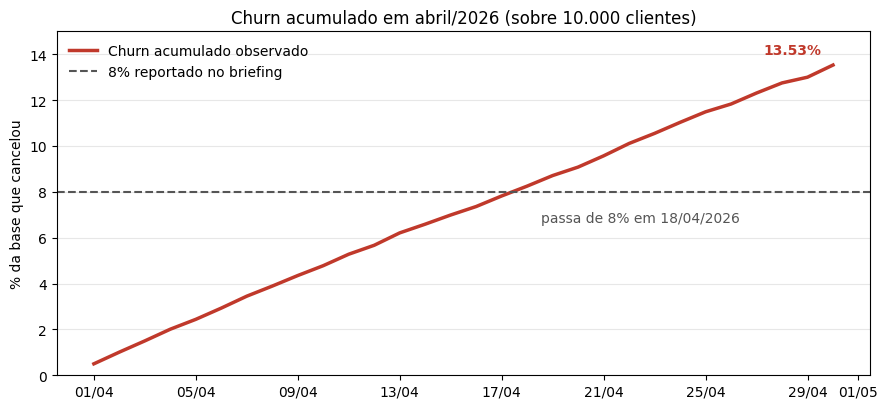

In [5]:
fig = ad.grafico_churn_acumulado(df)
fig.savefig(RAIZ / "reports" / "graficosexecutados" / "passo1_churn_acumulado_abril.png", dpi=150)
plt.show()

In [6]:
r1["por_dia"]

,cancelamentos,acumulado,churn_acumulado_%
data,,,
01/04/2026,50,50,0.50
02/04/2026,51,101,1.01
03/04/2026,49,150,1.50
04/04/2026,51,201,2.01
05/04/2026,43,244,2.44
06/04/2026,49,293,2.93
07/04/2026,52,345,3.45
08/04/2026,44,389,3.89
09/04/2026,46,435,4.35


## Passo 2 — Drivers por categoria

Para cada variável: churn por grupo, IC 95% (Wilson) e teste global de permutação (5.000 repetições, semente 0).
Limite de significância com Bonferroni para 9 testes: **p < 0,0056**. Grupos com n < 50 são agrupados, nunca descartados.

Cuidados: `tempo_resposta` só existe para quem abriu chamado; `transacoes_30d` mantém "ausente" e "0" separados (nada foi
alterado nos dados); tempo de casa usa 01/04/2026 como referência para não vazar o desfecho.

In [7]:
p2 = ad.analisar_drivers(df)
p2["resumo"]

,categoria,variavel,n,churn_pop_%,grupos,churn_min_%,churn_max_%,amplitude_pp,qui2,p_permutacao,significativo_bonferroni
0,Contextual,abriu_chamado,10000,13.53,2,10.50,22.50,12.00,232.39,0.0002,True
1,Contextual,tempo_resposta_quartis,2524,22.50,4,8.68,51.35,42.67,427.64,0.0002,True
2,Contextual,tempo_resposta_faixa_sla,2524,22.50,4,10.08,56.25,46.17,508.93,0.0002,True
3,Comportamental,notificacoes_7d,10000,13.53,13,6.13,25.82,19.69,530.03,0.0002,True
4,Comportamental,transacoes_30d,10000,13.53,6,12.24,14.88,2.64,7.31,0.1942,False
5,Demográfica,plano,10000,13.53,2,12.39,15.23,2.84,16.59,0.0002,True
6,Demográfica,estado,10000,13.53,23,7.56,19.02,11.46,55.56,0.0002,True
7,Demográfica,cidade,10000,13.53,58,7.56,23.17,15.61,123.54,0.0002,True
8,Controle,tempo_de_casa_dias,10000,13.53,4,12.86,14.05,1.19,2.24,0.5299,False


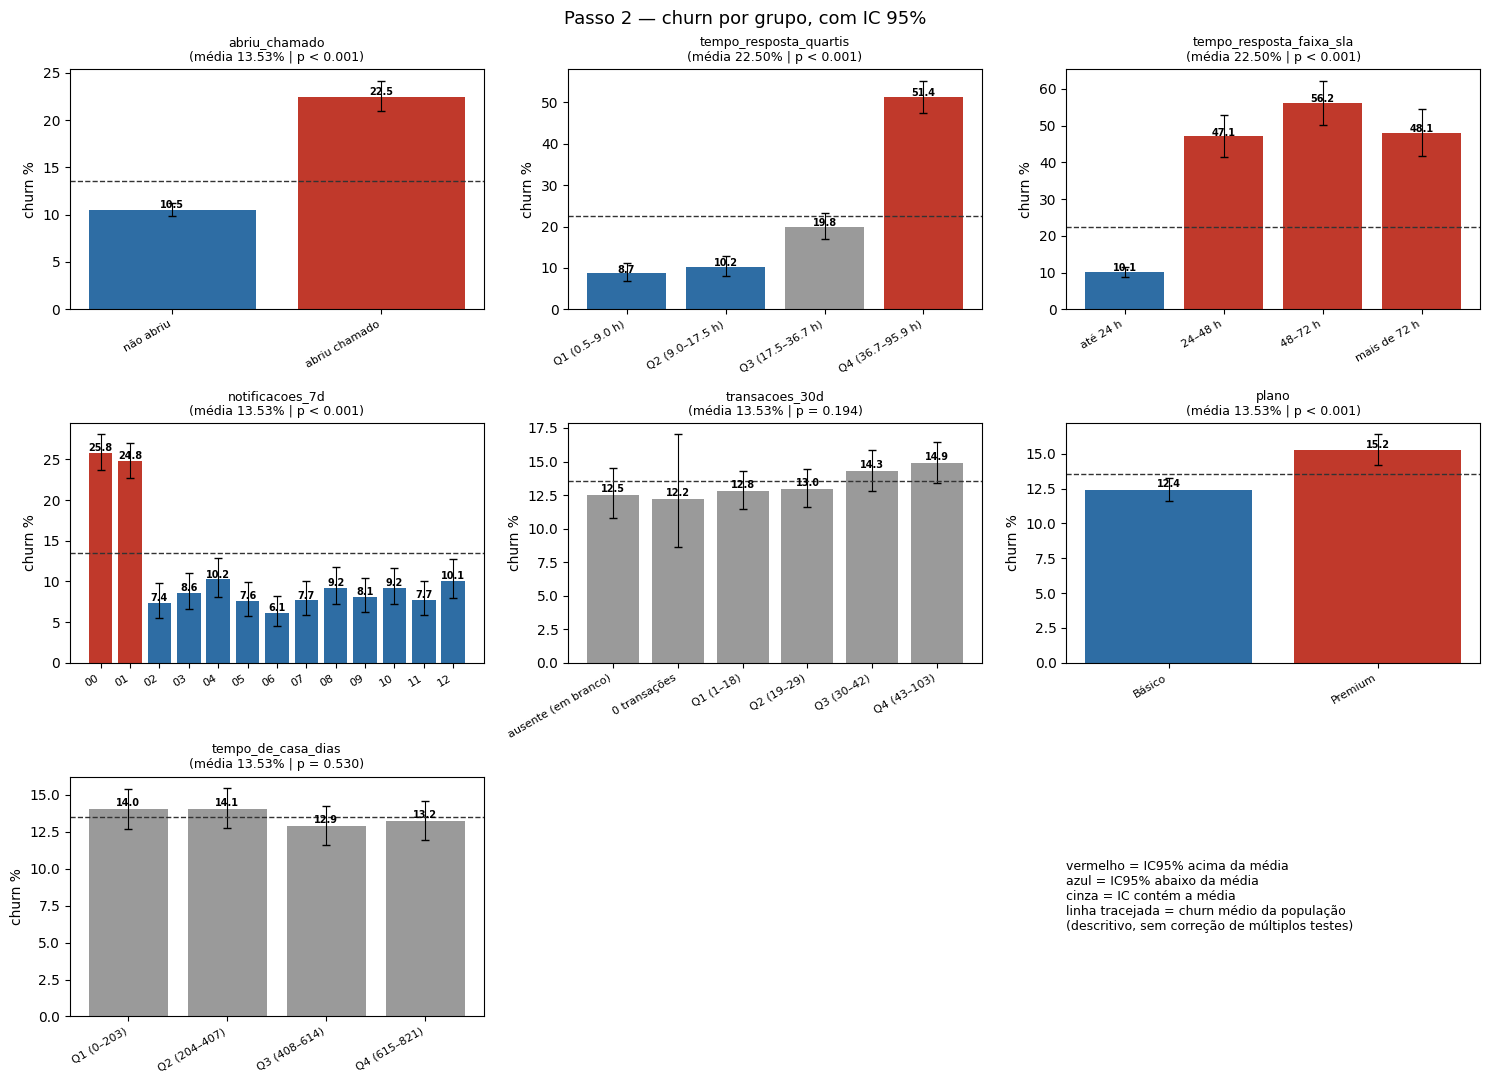

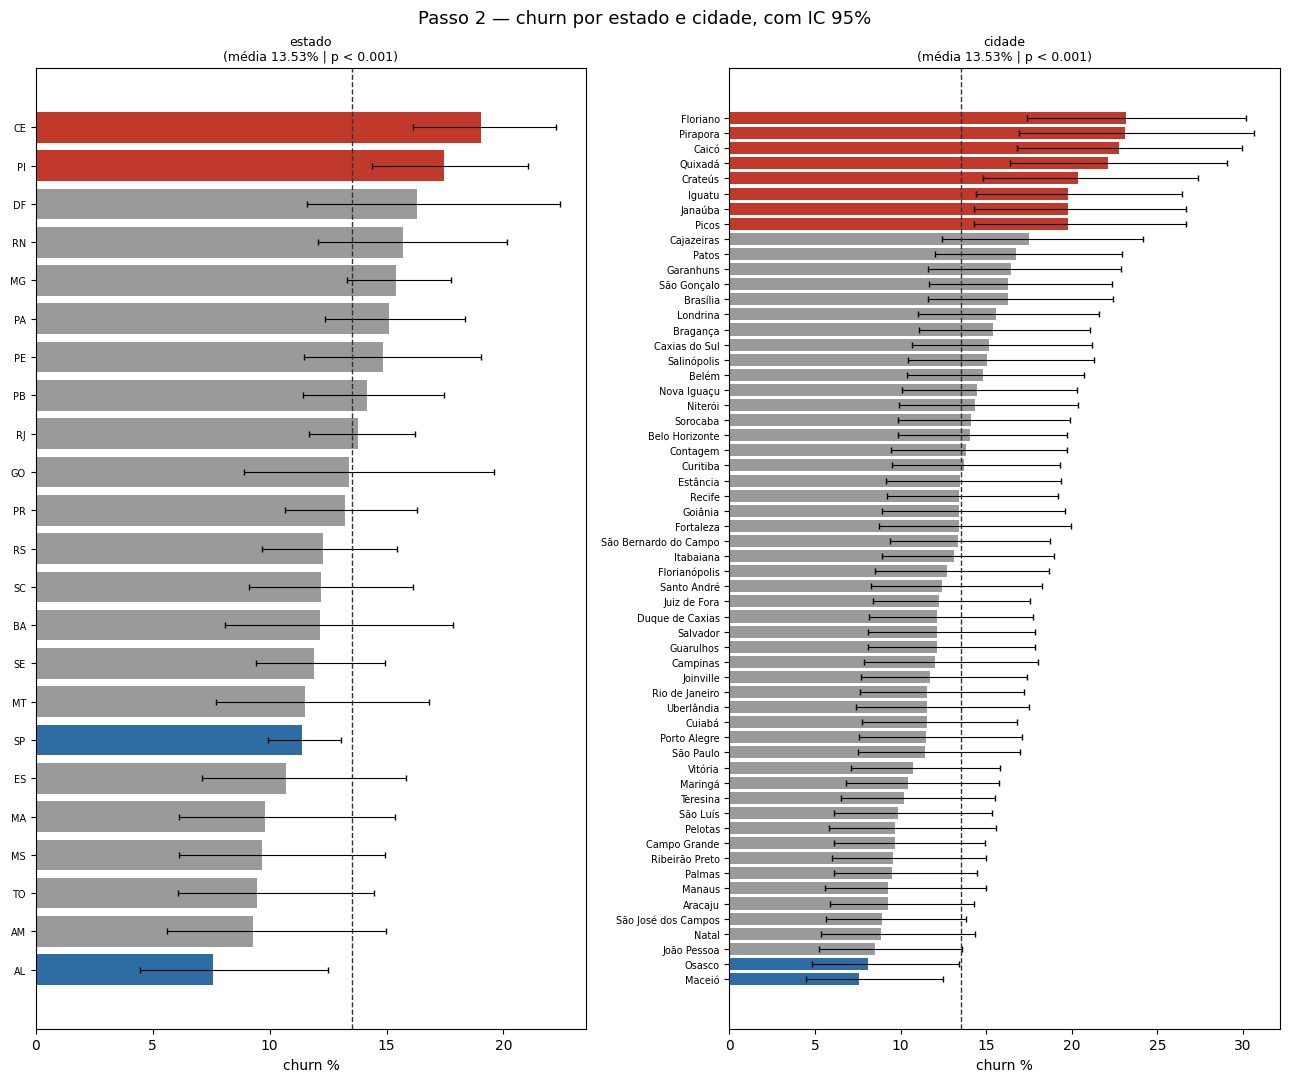

In [8]:
fig1, fig2 = ad.graficos_passo2(p2)
fig1.savefig(RAIZ / "reports" / "graficosexecutados" / "passo2_churn_por_variavel.png", dpi=130)
fig2.savefig(RAIZ / "reports" / "graficosexecutados" / "passo2_churn_geografia.png", dpi=130)
plt.show()

### `abriu_chamado`

In [9]:
print(p2["definicoes"]["abriu_chamado"]["nota"])
p2["variaveis"]["abriu_chamado"]["tabela"]

população: 10.000


,clientes,cancelaram,churn_%,ic95_inf_%,ic95_sup_%,dif_vs_media_pp,ic_exclui_a_media
grupo,,,,,,,
não abriu,7476,785,10.5,9.83,11.22,-3.03,True
abriu chamado,2524,568,22.5,20.92,24.17,8.97,True


### `tempo_resposta_quartis`

In [10]:
print(p2["definicoes"]["tempo_resposta_quartis"]["nota"])
p2["variaveis"]["tempo_resposta_quartis"]["tabela"]

população: só quem abriu chamado (n = 2.524)


,clientes,cancelaram,churn_%,ic95_inf_%,ic95_sup_%,dif_vs_media_pp,ic_exclui_a_media
grupo,,,,,,,
Q1 (0.5–9.0 h),634,55,8.68,6.73,11.12,-13.82,True
Q2 (9.0–17.5 h),634,65,10.25,8.13,12.86,-12.25,True
Q3 (17.5–36.7 h),625,124,19.84,16.90,23.15,-2.66,False
Q4 (36.7–95.9 h),631,324,51.35,47.45,55.23,28.85,True


### `tempo_resposta_faixa_sla`

In [11]:
print(p2["definicoes"]["tempo_resposta_faixa_sla"]["nota"])
p2["variaveis"]["tempo_resposta_faixa_sla"]["tabela"]

população: só quem abriu chamado; faixas de SLA em horas


,clientes,cancelaram,churn_%,ic95_inf_%,ic95_sup_%,dif_vs_media_pp,ic_exclui_a_media
grupo,,,,,,,
até 24 h,1746,176,10.08,8.75,11.58,-12.42,True
24–48 h,289,136,47.06,41.38,52.81,24.56,True
48–72 h,256,144,56.25,50.13,62.19,33.75,True
mais de 72 h,233,112,48.07,41.74,54.46,25.57,True


### `notificacoes_7d`

In [12]:
print(p2["definicoes"]["notificacoes_7d"]["nota"])
p2["variaveis"]["notificacoes_7d"]["tabela"]

população: 10.000


,clientes,cancelaram,churn_%,ic95_inf_%,ic95_sup_%,dif_vs_media_pp,ic_exclui_a_media
grupo,,,,,,,
00,1522,393,25.82,23.69,28.08,12.29,True
01,1527,379,24.82,22.72,27.05,11.29,True
02,580,43,7.41,5.55,9.84,-6.12,True
03,618,53,8.58,6.62,11.05,-4.95,True
04,605,62,10.25,8.08,12.92,-3.28,True
05,658,50,7.60,5.81,9.88,-5.93,True
06,636,39,6.13,4.52,8.27,-7.40,True
07,623,48,7.70,5.86,10.07,-5.83,True
08,638,59,9.25,7.24,11.75,-4.28,True


### `transacoes_30d`

In [13]:
print(p2["definicoes"]["transacoes_30d"]["nota"])
p2["variaveis"]["transacoes_30d"]["tabela"]

população: 10.000; ausente e 0 separados


,clientes,cancelaram,churn_%,ic95_inf_%,ic95_sup_%,dif_vs_media_pp,ic_exclui_a_media
grupo,,,,,,,
ausente (em branco),1215,152,12.51,10.77,14.49,-1.02,False
0 transações,237,29,12.24,8.66,17.02,-1.29,False
Q1 (1–18),2158,276,12.79,11.45,14.27,-0.74,False
Q2 (19–29),2221,288,12.97,11.63,14.43,-0.56,False
Q3 (30–42),2045,292,14.28,12.83,15.86,0.75,False
Q4 (43–103),2124,316,14.88,13.43,16.45,1.35,False


### `plano`

In [14]:
print(p2["definicoes"]["plano"]["nota"])
p2["variaveis"]["plano"]["tabela"]

população: 10.000


,clientes,cancelaram,churn_%,ic95_inf_%,ic95_sup_%,dif_vs_media_pp,ic_exclui_a_media
grupo,,,,,,,
Básico,5996,743,12.39,11.58,13.25,-1.14,True
Premium,4004,610,15.23,14.16,16.38,1.70,True


### `tempo_de_casa_dias`

In [15]:
print(p2["definicoes"]["tempo_de_casa_dias"]["nota"])
p2["variaveis"]["tempo_de_casa_dias"]["tabela"]

dias de cadastro até 01/04/2026


,clientes,cancelaram,churn_%,ic95_inf_%,ic95_sup_%,dif_vs_media_pp,ic_exclui_a_media
grupo,,,,,,,
Q1 (0–203),2506,351,14.01,12.70,15.42,0.48,False
Q2 (204–407),2499,351,14.05,12.74,15.46,0.52,False
Q3 (408–614),2497,321,12.86,11.60,14.23,-0.67,False
Q4 (615–821),2498,330,13.21,11.94,14.60,-0.32,False


### `estado` e `cidade` — 5 maiores e 5 menores

In [16]:
for nome in ("estado", "cidade"):
    t = p2["variaveis"][nome]["tabela"]
    print(nome, "| IC exclui a média em", int(t["ic_exclui_a_media"].sum()), "de", len(t), "grupos")
    display(pd.concat([t.head(5), t.tail(5)])[["clientes", "cancelaram", "churn_%", "ic95_inf_%", "ic95_sup_%", "dif_vs_media_pp"]])

estado | IC exclui a média em 4 de 23 grupos


,clientes,cancelaram,churn_%,ic95_inf_%,ic95_sup_%,dif_vs_media_pp
grupo,,,,,,
CE,631,120,19.02,16.15,22.26,5.49
PI,498,87,17.47,14.39,21.05,3.94
DF,178,29,16.29,11.59,22.42,2.76
RN,312,49,15.71,12.09,20.16,2.18
MG,1019,157,15.41,13.32,17.75,1.88
MA,163,16,9.82,6.13,15.35,-3.71
MS,176,17,9.66,6.12,14.92,-3.87
TO,190,18,9.47,6.08,14.48,-4.06
AM,151,14,9.27,5.60,14.96,-4.26


cidade | IC exclui a média em 10 de 59 grupos


,clientes,cancelaram,churn_%,ic95_inf_%,ic95_sup_%,dif_vs_media_pp
grupo,,,,,,
Floriano,164,38,23.17,17.37,30.20,9.64
Pirapora,143,33,23.08,16.93,30.63,9.55
Caicó,154,35,22.73,16.82,29.96,9.20
Quixadá,163,36,22.09,16.40,29.06,8.56
Crateús,157,32,20.38,14.82,27.36,6.85
Natal,158,14,8.86,5.35,14.32,-4.67
João Pessoa,176,15,8.52,5.23,13.58,-5.01
Osasco,160,13,8.12,4.81,13.40,-5.41
Maceió,172,13,7.56,4.47,12.50,-5.97


### Checagem de confusão: chamado × tempo de resposta, e sobreposição dos dois principais sinais

In [17]:
baixo = df["notificacoes_7d"] <= 1
lento = df["abriu_chamado"] & (df["tempo_resposta_chamado_h"] > 24)
conf = pd.DataFrame({
    "grupo": ["não abriu chamado", "chamado resolvido em até 24 h", "chamado acima de 24 h",
              "notificações 0–1", "notificações 2+", "nenhum dos dois sinais"],
    "clientes": [(~df["abriu_chamado"]).sum(), (df["abriu_chamado"] & ~lento).sum(), lento.sum(), baixo.sum(), (~baixo).sum(), (~baixo & ~lento).sum()],
    "churn_%": [df.loc[m, "churn_30d"].mean() * 100 for m in
                [~df["abriu_chamado"], df["abriu_chamado"] & ~lento, lento, baixo, ~baixo, ~baixo & ~lento]],
}).round(2)
conf

,grupo,clientes,churn_%
0,não abriu chamado,7476,10.50
1,chamado resolvido em até 24 h,1746,10.08
2,chamado acima de 24 h,778,50.39
3,notificações 0–1,3049,25.32
4,notificações 2+,6951,8.36
5,nenhum dos dois sinais,6408,6.13


## Passo 3 — Ranking por magnitude do efeito

- **Variáveis:** Cramér's V (bruto e corrigido para o número de grupos). Quanto maior, mais a variável separa quem cancela de quem fica.
- **Grupos:** todos comparados com a **mesma linha de base**, o churn da base inteira. IC de Wilson com z corrigido por Bonferroni
  para o total de grupos testados; "robusto" = o IC exclui a média da base.
- **Contrastes de 2 grupos:** risco relativo e diferença de risco, com IC 95%.
- **Excesso de cancelamentos** = cancelamentos observados − clientes × churn médio. Não é aditivo entre variáveis (os mesmos clientes
  aparecem em vários grupos).

Tudo é associação, não causa.

In [18]:
rank_var = ad.ranking_variaveis(p2)
rank_var

,variavel,categoria,n,grupos,cramers_v_bruto,cramers_v_corrigido,efeito,p_permutacao,significativo_bonferroni
0,tempo_resposta_faixa_sla,Contextual,2524,4,0.449,0.448,forte,0.0002,True
1,tempo_resposta_quartis,Contextual,2524,4,0.412,0.410,forte,0.0002,True
2,notificacoes_7d,Comportamental,10000,13,0.230,0.228,média,0.0002,True
3,abriu_chamado,Contextual,10000,2,0.152,0.152,média,0.0002,True
4,cidade,Demográfica,10000,59,0.111,0.081,pequena,0.0002,True
5,estado,Demográfica,10000,23,0.075,0.058,pequena,0.0002,True
6,plano,Demográfica,10000,2,0.041,0.039,desprezível,0.0002,True
7,transacoes_30d,Comportamental,10000,6,0.027,0.015,desprezível,0.1942,False
8,tempo_de_casa_dias,Controle,10000,4,0.015,0.000,desprezível,0.5299,False


In [19]:
rank_grp = ad.ranking_grupos(df, p2)
print("base:", rank_grp.attrs["base_%"], "% | comparações:", rank_grp.attrs["n_comparacoes"], "| z Bonferroni:", rank_grp.attrs["z_bonferroni"])
print("grupos robustos:", int(rank_grp["robusto"].sum()), "de", len(rank_grp))
rank_grp[rank_grp["robusto"]]

base: 13.53 % | comparações: 106 | z Bonferroni: 3.5
grupos robustos: 20 de 106


,variavel,grupo,clientes,cancelaram,churn_%,ic_inf_%,ic_sup_%,dif_vs_base_pp,risco_relativo,excesso_cancelamentos,robusto
0,tempo_resposta_faixa_sla,48–72 h,256,144,56.25,45.37,66.56,42.72,4.16,109,True
1,tempo_resposta_quartis,Q4 (36.7–95.9 h),631,324,51.35,44.43,58.21,37.82,3.80,239,True
2,tempo_resposta_faixa_sla,mais de 72 h,233,112,48.07,37.01,59.32,34.54,3.55,80,True
3,tempo_resposta_faixa_sla,24–48 h,289,136,47.06,37.12,57.23,33.53,3.48,97,True
4,notificacoes_7d,00,1522,393,25.82,22.10,29.93,12.29,1.91,187,True
5,notificacoes_7d,01,1527,379,24.82,21.17,28.87,11.29,1.83,172,True
6,cidade,Floriano,164,38,23.17,13.76,36.30,9.64,1.71,16,True
9,abriu_chamado,abriu chamado,2524,568,22.50,19.73,25.54,8.97,1.66,227,True
11,notificacoes_7d,06,636,39,6.13,3.56,10.36,-7.40,0.45,-47,True
13,tempo_resposta_quartis,Q3 (17.5–36.7 h),625,124,19.84,14.86,25.97,6.31,1.47,39,True


In [20]:
ad.contrastes_binarios(df)

,contraste,n_exposto,n_referencia,churn_exposto_%,churn_referencia_%,risco_relativo,rr_ic95,dif_pp,dif_ic95_pp
0,Chamado > 24 h vs. chamado <= 24 h (só quem ab...,778,1746,50.39,10.08,5.00,4.27 a 5.85,40.31,36.52 a 44.09
1,Chamado > 24 h vs. resto da base,778,9222,50.39,10.42,4.84,4.41 a 5.30,39.96,36.40 a 43.53
2,Notificações 0-1 vs. 2 ou mais,3049,6951,25.32,8.36,3.03,2.74 a 3.34,16.96,15.29 a 18.64
3,Abriu chamado vs. não abriu,2524,7476,22.50,10.50,2.14,1.94 a 2.36,12.00,10.23 a 13.77
4,Chamado <= 24 h vs. não abriu chamado,1746,7476,10.08,10.50,0.96,0.82 a 1.12,-0.42,-1.99 a 1.15
5,Premium vs. Básico,4004,5996,15.23,12.39,1.23,1.11 a 1.36,2.84,1.45 a 4.23


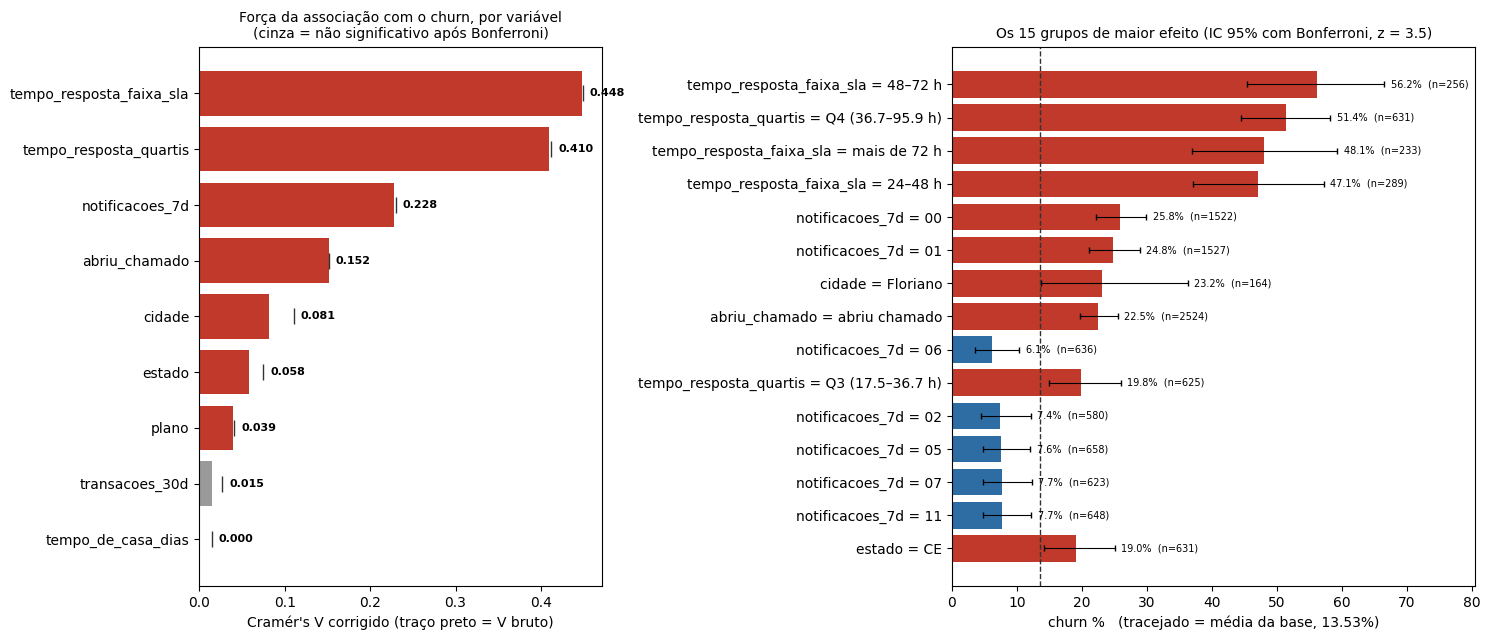

In [21]:
fig3 = ad.grafico_passo3(rank_var, rank_grp)
fig3.savefig(RAIZ / "reports" / "graficosexecutados" / "passo3_ranking_drivers.png", dpi=130)
plt.show()

In [22]:
# Geografia depois da correção de Bonferroni: quais estados e cidades sobrevivem?
rank_grp[(rank_grp["variavel"].isin(["estado", "cidade"]))].head(8)[["variavel", "grupo", "clientes", "churn_%", "ic_inf_%", "ic_sup_%", "robusto"]]

,variavel,grupo,clientes,churn_%,ic_inf_%,ic_sup_%,robusto
6,cidade,Floriano,164,23.17,13.76,36.30,True
7,cidade,Pirapora,143,23.08,13.18,37.21,False
8,cidade,Caicó,154,22.73,13.19,36.27,False
10,cidade,Quixadá,163,22.09,12.90,35.16,False
12,cidade,Crateús,157,20.38,11.49,33.56,False
14,cidade,Iguatu,167,19.76,11.22,32.42,False
15,cidade,Janaúba,157,19.75,11.01,32.85,False
16,cidade,Picos,157,19.75,11.01,32.85,False


## Passo 4 — Combinação dos top drivers

Sinais: **notificações 0–1** e **chamado > 24 h** (os dois de maior V no Passo 3). Perguntas:
1. Como o churn muda quando os dois aparecem juntos?
2. Os efeitos **se somam, se multiplicam ou se reforçam**? (observado vs. esperado se fossem independentes, IC por bootstrap)
3. Plano e geografia continuam importando **depois** de controlar pelos dois sinais?

Sem regressão logística (biblioteca fora da stack). Associação, não causa.

In [23]:
seg = ad.segmentos_risco(df)
seg

,segmento,clientes,cancelaram,churn_%,ic95_inf_%,ic95_sup_%,%_da_base,%_dos_cancelamentos,n_suficiente
0,nenhum sinal,6408,393,6.13,5.57,6.75,64.1,29.0,True
1,só notificações 0-1,2814,568,20.18,18.74,21.71,28.1,42.0,True
2,só chamado > 24 h,543,188,34.62,30.74,38.72,5.4,13.9,True
3,os dois sinais,235,204,86.81,81.88,90.55,2.4,15.1,True


In [24]:
baixo, lento = ad.sinais_de_risco(df)
ad.tabela_cruzada(df, ad.situacao_chamado(df), baixo.map({True: "notif 0-1", False: "notif 2+"}))

,linha,coluna,clientes,cancelaram,churn_%,ic95_inf_%,ic95_sup_%,%_da_base,%_dos_cancelamentos,n_suficiente
0,chamado > 24 h,notif 0-1,235,204,86.81,81.88,90.55,2.4,15.1,True
1,chamado > 24 h,notif 2+,543,188,34.62,30.74,38.72,5.4,13.9,True
2,chamado ≤ 24 h,notif 0-1,537,114,21.23,17.98,24.89,5.4,8.4,True
3,chamado ≤ 24 h,notif 2+,1209,62,5.13,4.02,6.52,12.1,4.6,True
4,não abriu chamado,notif 0-1,2277,454,19.94,18.35,21.63,22.8,33.6,True
5,não abriu chamado,notif 2+,5199,331,6.37,5.73,7.06,52.0,24.5,True


### Interação: observado vs. esperado se os sinais fossem independentes

In [25]:
inter = ad.interacao(df)
pd.Series(inter, name="valor").to_frame()

,valor
churn_nenhum_%,6.13
churn_so_baixo_%,20.18
churn_so_lento_%,34.62
churn_ambos_observado_%,86.81
esperado_aditivo_%,48.67
esperado_multiplicativo_%,113.95
interacao_aditiva_pp,38.13
interacao_aditiva_ic95_pp,31.97 a 44.28
razao_multiplicativa,0.762
razao_multiplicativa_ic95,0.641 a 0.911


### Efeito de cada driver com e sem ajuste (Mantel-Haenszel)

In [26]:
ad.efeito_ajustado(df)

,driver,clientes_expostos,rr_bruto,rr_ajustado,rr_ajustado_ic95
0,Chamado > 24 h (ajustado por notificações 0-1),778,4.84,4.85,4.47 a 5.27
1,Notificações 0-1 (ajustado por chamado > 24 h),3049,3.03,3.04,2.77 a 3.33
2,Premium (ajustado pelos 2 sinais),4004,1.23,1.22,1.11 a 1.33
3,Estado = CE (ajustado pelos 2 sinais),631,1.45,1.52,1.31 a 1.77
4,Cidade = Floriano (ajustado pelos 2 sinais),164,1.73,1.69,1.33 a 2.15


In [27]:
ad.geografia_sem_sinais(df)

,variavel,clientes_no_segmento,churn_segmento_%,qui2,p_permutacao
0,plano,6408,6.13,3.03,0.0874
1,estado,6408,6.13,36.95,0.0272
2,cidade,6408,6.13,74.99,0.0696


### Dose-resposta: faixa de SLA × notificações (só quem abriu chamado)

In [28]:
sla = p2["definicoes"]["tempo_resposta_faixa_sla"]["grupo"]
ch = df.loc[sla.index]
ad.tabela_cruzada(ch, sla, baixo.loc[sla.index].map({True: "notif 0-1", False: "notif 2+"}))

,linha,coluna,clientes,cancelaram,churn_%,ic95_inf_%,ic95_sup_%,%_da_base,%_dos_cancelamentos,n_suficiente
0,24–48 h,notif 0-1,78,69,88.46,79.50,93.81,3.1,12.1,True
1,24–48 h,notif 2+,211,67,31.75,25.85,38.31,8.4,11.8,True
2,48–72 h,notif 0-1,85,67,78.82,68.99,86.16,3.4,11.8,True
3,48–72 h,notif 2+,171,77,45.03,37.76,52.51,6.8,13.6,True
4,até 24 h,notif 0-1,537,114,21.23,17.98,24.89,21.3,20.1,True
5,até 24 h,notif 2+,1209,62,5.13,4.02,6.52,47.9,10.9,True
6,mais de 72 h,notif 0-1,72,68,94.44,86.57,97.82,2.9,12.0,True
7,mais de 72 h,notif 2+,161,44,27.33,21.03,34.68,6.4,7.7,True


### Tamanho do problema associado aos sinais

In [29]:
pd.Series(ad.excesso_atribuivel(df), name="valor").to_frame()

,valor
clientes_com_algum_sinal,3592.00
%_da_base,35.90
cancelamentos_com_algum_sinal,960.00
%_dos_cancelamentos,71.00
churn_sem_sinais_%,6.13
cancelamentos_esperados_se_sem_sinais,220.00
excesso_de_cancelamentos,740.00
excesso_%_do_total,54.70
churn_da_base_se_todos_fossem_sem_sinais_%,6.13


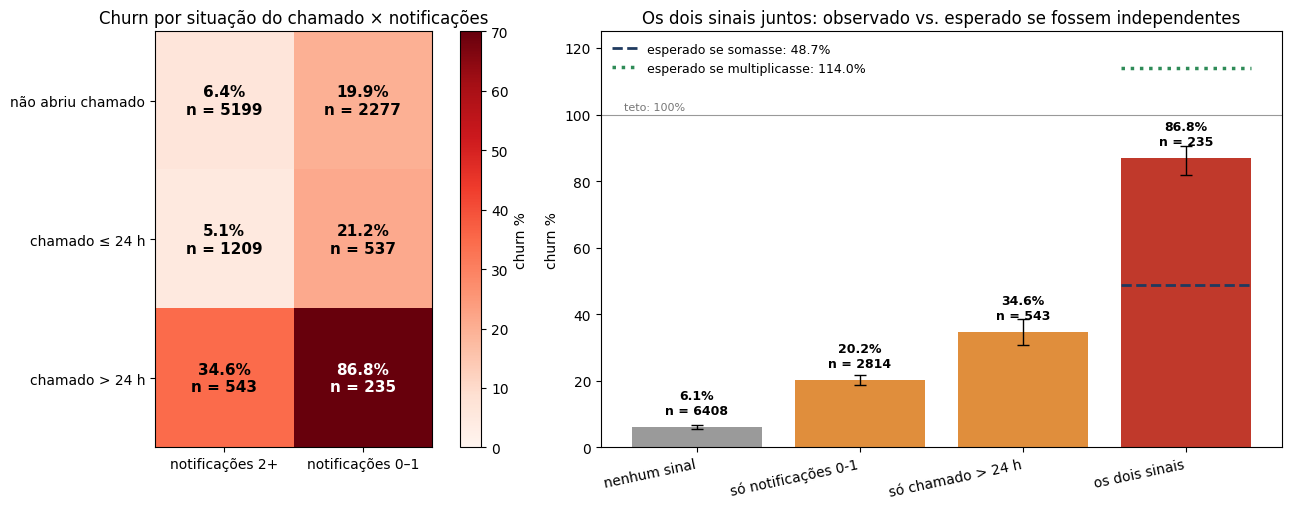

In [30]:
fig4 = ad.grafico_passo4(df, seg, inter)
fig4.savefig(RAIZ / "reports" / "graficosexecutados" / "passo4_combinacao_drivers.png", dpi=130)
plt.show()

## Aprofundamento — notificações

Funções em `scripts/analisar_notificacoes.py`. Pergunta: clientes com poucas notificações (0–1 em `notificacoes_7d`) se comportam de forma diferente?

**Atenção:** não há dicionário de dados. Não sabemos se a janela de 7 dias é "os 7 primeiros dias após o cadastro" ou outra.

In [31]:
import analisar_notificacoes as an
pd.Series(an.checar_janela(df), name="valor").to_frame()

,valor
churners_total,1353.000
churners_que_cancelaram_antes_de_7_dias_de_casa,3.000
notificacoes_media_desses,1.000
notificacoes_media_dos_demais_churners,3.370
spearman_notificacoes_vs_data_de_cadastro,-0.004
clientes_cadastrados_nos_ultimos_7_dias_da_base,111.000
notificacoes_media_dos_cadastrados_nos_ultimos_7_dias,5.420
notificacoes_media_dos_demais,5.060


### 0–1 notificação vs. 2+ em outras características

In [32]:
an.perfil_por_grupo(df)

,caracteristica,grupo_0-1,grupo_2+,diferenca,p_permutacao,significativo_bonferroni
0,"transacoes_30d (média, onde informado)",30.72,30.80,-0.07,0.8588,False
1,transacoes_30d zero ou ausente (%),14.23,14.65,-0.41,0.6005,False
2,"ticket médio (média, só valores normais)",87.66,87.07,0.59,0.6579,False
3,ticket = 0 (%),14.23,14.65,-0.41,0.6005,False
4,ticket extremo >= 10.000 (%),6.79,6.76,0.03,0.9664,False
5,abriu chamado (%),25.32,25.21,0.11,0.9224,False
6,"tempo de resposta (média h, só quem abriu)",26.63,26.29,0.34,0.7413,False
7,chamado lento > 24 h (% de quem abriu),30.44,30.99,-0.55,0.8234,False
8,plano Premium (%),40.28,39.94,0.34,0.7608,False
9,"tempo de casa (média, dias)",412.50,408.51,3.99,0.4397,False


### 0 vs. 1, e gradiente entre 2 e 12

In [33]:
pd.json_normalize(an.zero_vs_um_e_gradiente(df)).T.rename(columns={0: "valor"})

,valor
zero_vs_um.churn_zero_%,25.82
zero_vs_um.churn_um_%,24.82
zero_vs_um.RR,1.04
zero_vs_um.RR_ic95,0.92 a 1.18
tendencia_2_a_12.spearman_nivel_vs_churn,0.0111
tendencia_2_a_12.p_permutacao,0.3683
tendencia_2_a_12.churn_2_a_12_%,8.36


### Efeito (0–1 vs. 2+) por subgrupo

In [34]:
an.efeito_por_estrato(df)

,estrato,grupo,n_0-1,n_2+,churn_0-1_%,churn_2+_%,risco_relativo,rr_ic95
0,plano,Básico,1821,4175,23.61,7.50,3.15,2.75 a 3.60
1,plano,Premium,1228,2776,27.85,9.65,2.88,2.50 a 3.34
2,"tempo de casa (quartis, dias)",Q1 (0–203),745,1761,27.65,8.23,3.36,2.76 a 4.08
3,"tempo de casa (quartis, dias)",Q2 (204–407),745,1754,25.64,9.12,2.81,2.32 a 3.40
4,"tempo de casa (quartis, dias)",Q3 (408–614),804,1693,22.89,8.09,2.83,2.30 a 3.47
5,"tempo de casa (quartis, dias)",Q4 (615–821),755,1743,25.30,7.97,3.17,2.59 a 3.88
6,situação do chamado,chamado > 24 h,235,543,86.81,34.62,2.51,2.21 a 2.84
7,situação do chamado,chamado ≤ 24 h,537,1209,21.23,5.13,4.14,3.09 a 5.54
8,situação do chamado,não abriu chamado,2277,5199,19.94,6.37,3.13,2.74 a 3.58
